# Load library

In [ ]:
#Import lib
import pandas as pd
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from my_useful_functions import calculate_performance_statistical_parity,calculate_performance_equalized_odds,calculate_performance_equal_opportunity,calculate_performance_predictive_parity,calculate_performance_predictive_equality,calculate_performance_treatment_equality
from sklearn import preprocessing
# DT
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
# NB
from sklearn.naive_bayes import GaussianNB
# MLP
from sklearn.neural_network import MLPClassifier
# kNN
from sklearn.neighbors import KNeighborsClassifier
# Adafair
from AdaFair import AdaFair 
# Agarwal
from exponentiated_gradient_reduction import ExponentiatedGradientReduction
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from compute_abroca import *
import numpy as np
import sklearn.metrics as metrics 
from scipy import interpolate
from scipy import integrate
import matplotlib.pyplot as plt
import matplotlib
import pandas as pd
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl
from sklearn import metrics
import seaborn as sns
import seaborn as sn


import seaborn; seaborn.set_style('whitegrid')
from sklearn.preprocessing import label_binarize
from sklearn.preprocessing import OrdinalEncoder

#from aif360.datasets import StandardDataset
#from aif360.metrics import BinaryLabelDatasetMetric, ClassificationMetric

%matplotlib inline

from pomegranate import *
import pygraphviz
numpy.random.seed(0)
numpy.set_printoptions(suppress=True)
from sklearn.model_selection import train_test_split
import networkx
from pomegranate.utils import plot_networkx
#matplotlib.use('TkAgg')
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[inFairness]'


# Data analysis

## Statistic Information

In [2]:
df=pd.read_csv("/Users/doanthang/Desktop/Code/ba-fairness-aware/data/20260203_103546.csv")
risk={1:"Good", 2:"Bad"}
df["class-label"]=df["class-label"].map(risk)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 22 columns):
 #   Column                                 Non-Null Count  Dtype
---  ------                                 --------------  -----
 0   checking-account                       1000 non-null   str  
 1   duration                               1000 non-null   int64
 2   credit-history                         1000 non-null   str  
 3   purpose                                1000 non-null   str  
 4   credit-amount                          1000 non-null   int64
 5   savings-account                        1000 non-null   str  
 6   employment-since                       1000 non-null   str  
 7   installment-rate                       1000 non-null   int64
 8   other-debtors                          1000 non-null   str  
 9   residence-since                        1000 non-null   int64
 10  property                               1000 non-null   str  
 11  age                                    100

In [4]:
#statistical_parity
def statistical_parity_difference(dataset, protected,classes,majority_group,minority_group,positive_value):
    ratio = round(pd.crosstab(dataset[protected], dataset[classes]).div(pd.crosstab(dataset[protected], dataset[classes]).apply(sum,1),0),4)*100
    #return ratio
    return ratio.loc[majority_group][positive_value]-ratio.loc[minority_group][positive_value]

In [5]:
def basic_info(dataset,class_label,positive_value,negative_value,protected_attr,majority_group,minority_group):
    categorical_columns = (dataset.select_dtypes(['category', 'object']).columns)
    numeric_columns = (dataset.select_dtypes(['number']).columns)
    for attr in dataset.keys():
        if attr in categorical_columns:    
            print(attr ,' & Categorical & ',len(dataset[attr].value_counts()),'& &',dataset[attr].isnull().sum(),'\\\\')
        else:           
            print(attr,'& Numerical &',len(dataset[attr].value_counts()),'&',min(dataset[attr]),"-",max(dataset[attr]),'&',dataset[attr].isnull().sum(),'\\\\')  
    
    print('Class distribution:',dataset[class_label].value_counts())
    print('Class imbalance:',len(dataset.loc[dataset[class_label]==negative_value])/len(dataset.loc[dataset[class_label]==positive_value]))
    print('statistical parity:',statistical_parity_difference(dataset,protected_attr,class_label,majority_group,minority_group,positive_value))

In [6]:
basic_info(df,class_label="class-label",positive_value="Good",negative_value="Bad",
           protected_attr="sex",majority_group='male',minority_group='female')

checking-account  & Categorical &  4 & & 0 \\
duration & Numerical & 15 & 6 - 60 & 0 \\
credit-history  & Categorical &  6 & & 0 \\
purpose  & Categorical &  10 & & 0 \\
credit-amount & Numerical & 311 & 350 - 15000 & 0 \\
savings-account  & Categorical &  6 & & 0 \\
employment-since  & Categorical &  5 & & 0 \\
installment-rate & Numerical & 4 & 1 - 4 & 0 \\
other-debtors  & Categorical &  3 & & 0 \\
residence-since & Numerical & 4 & 1 - 4 & 0 \\
property  & Categorical &  6 & & 0 \\
age & Numerical & 47 & 20 - 68 & 0 \\
other-installment  & Categorical &  3 & & 0 \\
housing  & Categorical &  4 & & 0 \\
existing-credits & Numerical & 3 & 1 - 3 & 0 \\
job  & Categorical &  7 & & 0 \\
number-people-provide-maintenance-for & Numerical & 2 & 1 - 2 & 0 \\
telephone  & Categorical &  2 & & 0 \\
foreign-worker  & Categorical &  2 & & 0 \\
sex  & Categorical &  2 & & 0 \\
marital-status  & Categorical &  3 & & 0 \\
class-label  & Categorical &  1 & & 500 \\
Class distribution: class-label
Goo

## Missing value

In [7]:
#Check missing values
print('Missing values')
for i,j in zip(df.columns,(df.values.astype(str) == '?').sum(axis = 0)):
    if j > 0:
        print(str(i) + ': ' + str(j) + ' records')
print("---------------------------------")
df.isnull().sum()

Missing values
---------------------------------


checking-account                           0
duration                                   0
credit-history                             0
purpose                                    0
credit-amount                              0
savings-account                            0
employment-since                           0
installment-rate                           0
other-debtors                              0
residence-since                            0
property                                   0
age                                        0
other-installment                          0
housing                                    0
existing-credits                           0
job                                        0
number-people-provide-maintenance-for      0
telephone                                  0
foreign-worker                             0
sex                                        0
marital-status                             0
class-label                              500
dtype: int

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 22 columns):
 #   Column                                 Non-Null Count  Dtype
---  ------                                 --------------  -----
 0   checking-account                       1000 non-null   str  
 1   duration                               1000 non-null   int64
 2   credit-history                         1000 non-null   str  
 3   purpose                                1000 non-null   str  
 4   credit-amount                          1000 non-null   int64
 5   savings-account                        1000 non-null   str  
 6   employment-since                       1000 non-null   str  
 7   installment-rate                       1000 non-null   int64
 8   other-debtors                          1000 non-null   str  
 9   residence-since                        1000 non-null   int64
 10  property                               1000 non-null   str  
 11  age                                    100

## Bayesian Network

In [8]:
def plot_bayesian_network(a, X, labels, name):
  model = BayesianNetwork.from_samples(X, algorithm='exact',constraint_graph=a,state_names=labels)
  plt.figure(figsize=(15, 12),dpi=400)
  model.plot()
  print(model.structure)
  plt.savefig(name, bbox_inches='tight')

In [9]:
def german_credit():
  df=pd.read_csv("/Users/doanthang/Desktop/Code/ba-fairness-aware/data/20260203_103546.csv")
  print("Length:",len(df))
  print("Number of attribute:",len(df.columns))
  
  print(df['class-label'].value_counts())

  X = df.values
  for i in range(len(list(df.keys()))):
    if len(pd.unique(df[df.keys()[i]])) == 2:
      print(i,list(df.keys())[i], len(pd.unique(df[df.keys()[i]]))) 
  labels=list(df.keys())

  X[:,1]=np.array([0 if v<=6 else 1 if v>6 and v<=12 else 2 for v in X[:,1]]) #duration
  X[:,4]=np.array([0 if v<=2000 else 1 if v>2000 and v<=5000 else 2 for v in X[:,4]]) #credit amount
  X[:,11]=np.array([0 if v<25 else 1 for v in X[:,11]]) #age
 
  a = networkx.DiGraph()
  b = tuple((0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20))
  c= tuple((21, ))
  a.add_edge(b,c)
  a.add_edge(b,b)

  return a, X, labels

Length: 1000
Number of attribute: 22
class-label
1    500
0    500
Name: count, dtype: int64
16 number-people-provide-maintenance-for 2
17 telephone 2
18 foreign-worker 2
19 sex 2
21 class-label 2
((12, 17), (4,), (0,), (4,), (12,), (0,), (0, 17), (4,), (0,), (6,), (13,), (6, 17), (), (11, 17), (2,), (4,), (19, 20), (15,), (19,), (11, 20), (9,), (0, 12))


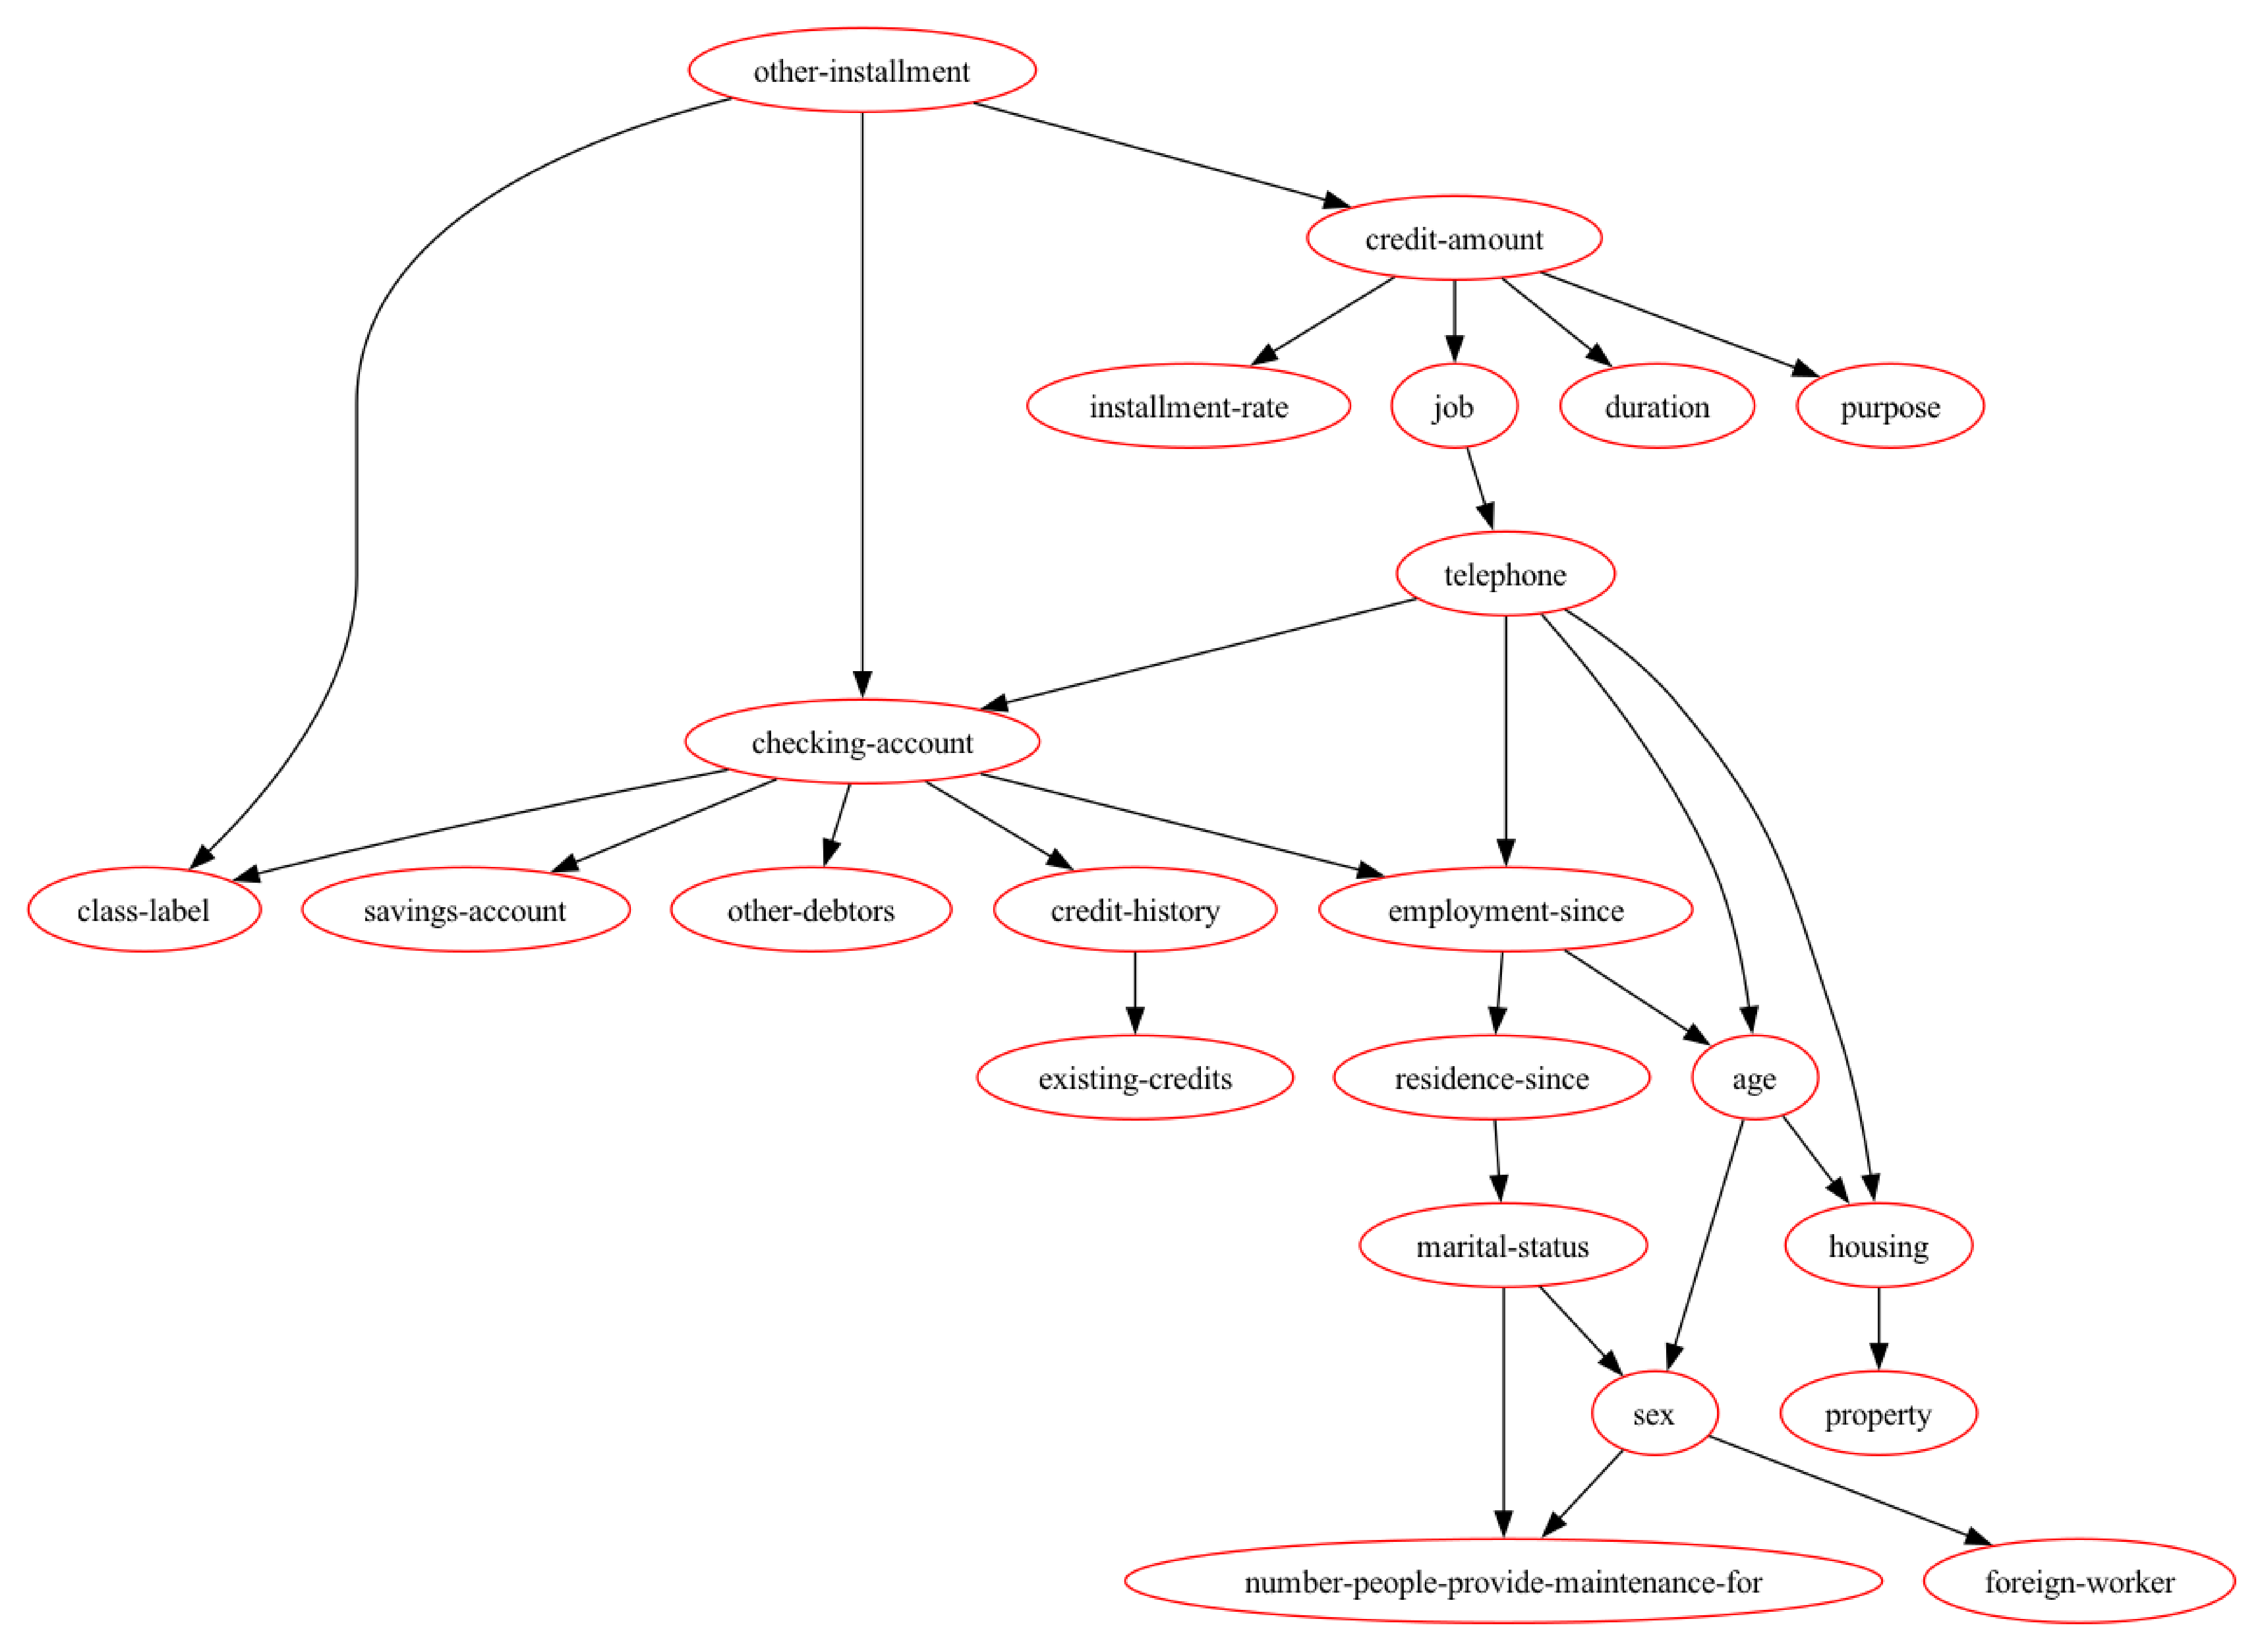

In [10]:
a, X, labels = german_credit()
plot_bayesian_network(a, X, labels, 'German.BN.synthetic.pdf')

In [11]:
def german_credit_plot_1():
  df=pd.read_csv("/Users/doanthang/Desktop/Code/ba-fairness-aware/data/20260203_103546.csv")
  print("Length:",len(df))
  print("Number of attribute:",len(df.columns))

  print(len(df[(df['credit-amount'] < 5000) & (df['credit-amount'] >= 2000) & (df["duration"] > 48)]))

  a24 = [422, 284, 64]
  a48 = [10, 96, 108]
  a72 = [108, 0, 16]

  
  groups = ("<= 2000", "2000 - 5000", "> 5000")
  groups_value = {
      '0-2 years': (422, 284, 64),
      '2-4 years': (10, 96, 108),
      '4-6 years': (108, 0, 16),
  }

  x = np.arange(len(groups))  # the label locations
  width = 0.2  # the width of the bars
  multiplier = 0
  

  fig, ax = plt.subplots(layout='constrained', figsize=(12, 6))

  column_sums = np.sum(list(groups_value.values()), axis=0)
  for attribute, measurement in groups_value.items():
      offset = width * multiplier
      percentage = [100 * value / column_sums[index] for index, value in enumerate(measurement)]
      # rects = ax.bar(x + offset, [round(_, 2) for _ in percentage], width, label=attribute)
      rects = ax.bar(x + offset, measurement, width, label=attribute)
      ax.bar_label(rects, labels=[f"{(round(_, 2))}%" for _ in percentage], padding=4)
      multiplier += 1

  # Add some text for labels, title and custom x-axis tick labels, etc.
  ax.set_ylabel('Population', fontsize=14, fontweight='bold')
  ax.set_xlabel('Credit amount', fontsize=14, fontweight='bold')
  # ax.set_title('Penguin attributes by species')
  ax.set_xticks(x + width, groups)
  plt.legend(title="Duration", loc='upper left', bbox_to_anchor=(0.3, 1))

  plt.show()

Length: 1000
Number of attribute: 22
0


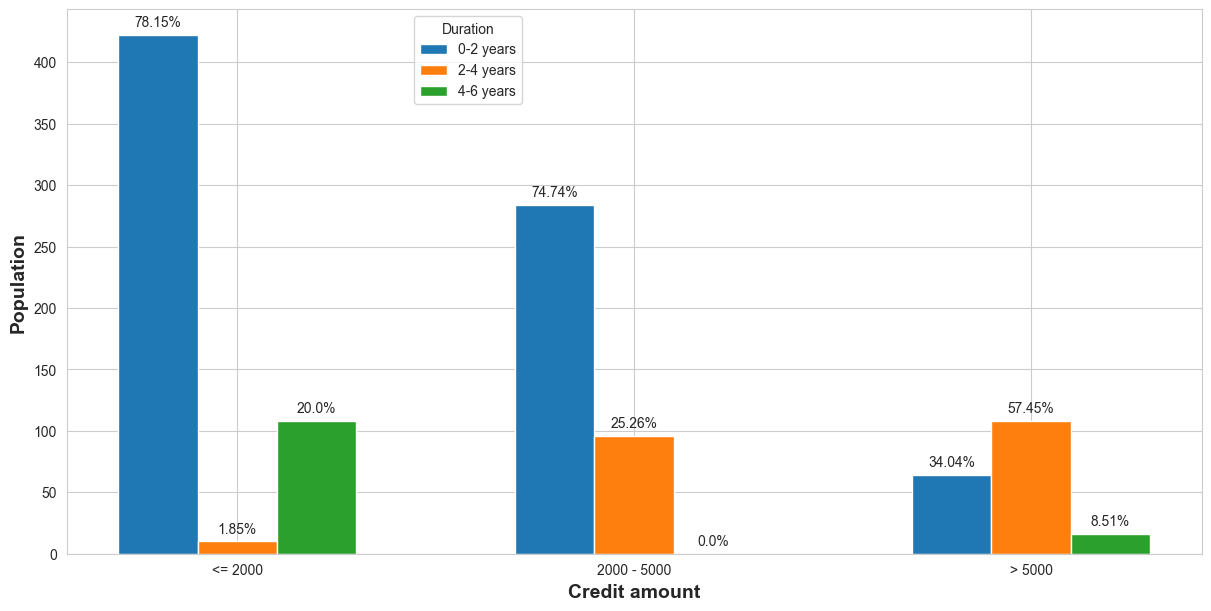

In [12]:
german_credit_plot_1()

In [13]:
import matplotlib.ticker as mtick
def plot_2_variable(dataset,var1, var2, width=0.5, wide=9,height=5,legend="", xlabel="", logy=False,verbose=True,indexlist="",index=False):
    
    var1_var2_ratio=round(pd.crosstab(dataset[var1], dataset[var2]).div(pd.crosstab(dataset[var1], dataset[var2]).apply(sum,1),0),3)*100
    var1_var2 =  pd.crosstab(dataset[var1], dataset[var2])
    if verbose:
        print(var1_var2)
        
    if index:
        var1_var2 = var1_var2.reindex(indexlist)
        var1_var2_ratio = var1_var2_ratio.reindex(indexlist)
    
    ax = var1_var2.plot(kind='bar',width=width,figsize=(wide,height)
                     ,logy=logy
                     )
    #x = hour_income_gender.plot(kind ='bar',stacked=False)
    xlocs, xlabs = plt.xticks()
    for i in range(len(var1_var2)):
        for j in range(len(var1_var2.iloc[i])):
            plt.text(xlocs[i]-0.35+j*0.3, var1_var2.iloc[i][j] + 2,str(round(var1_var2_ratio.iloc[i][j],1))+"%" )
    #plt.title('Distribution of '+ title+ ' across '+ legend)
    plt.ylabel('Population',fontsize=14,fontweight='bold')
    plt.xlabel(xlabel,fontsize=14,fontweight='bold')
    
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    plt.rc('xtick',labelsize=13)
    plt.rc('ytick',labelsize=13)
    plt.xticks(rotation=0)
    plt.legend(title=legend,prop={'size': 12})
    filename=var1+"_"+var2+".pdf"
    plt.savefig(filename,bbox_inches='tight')    
    

class-label       Good
checking-account      
0 <= <200 DM        80
<0 DM               18
>= 200 DM           53
no account         349


KeyError: 0

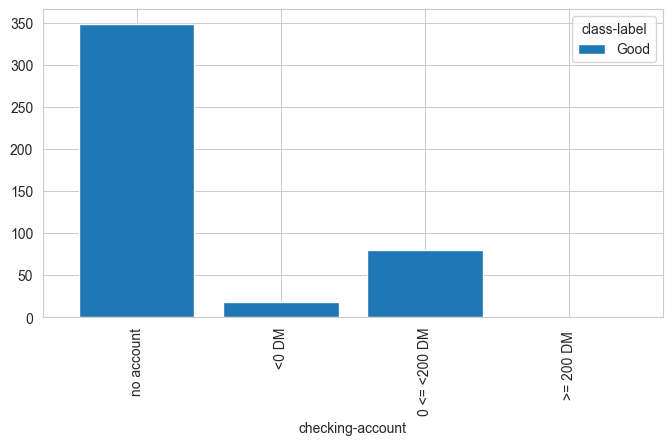

In [14]:
plot_2_variable(df,var1='checking-account', var2='class-label', width=0.8, wide=8,height=4,
                legend="Class", xlabel="Status of checking account", logy=False,verbose=True,indexlist=["no account", "<0 DM","0 <= <200 DM",">= 200 DM "],index=True)

<Axes: xlabel='credit-amount'>

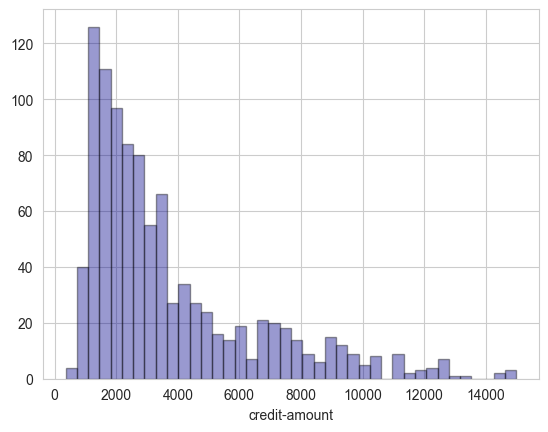

In [15]:
#Credit amount
sns.distplot(df['credit-amount'], hist=True, kde=False, 
             bins=40, color = 'darkblue', 
             hist_kws={'edgecolor':'black'},
             kde_kws={'linewidth': 4})

<AxesSubplot:xlabel='duration'>

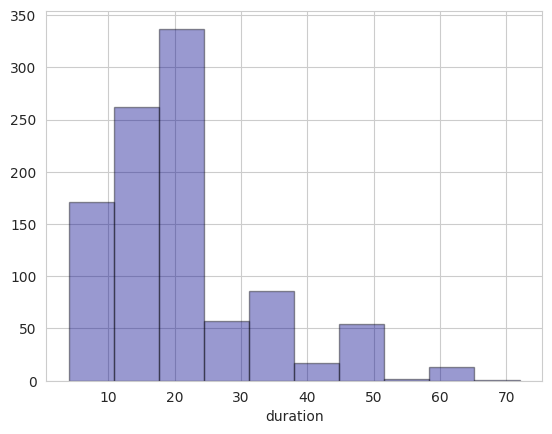

In [36]:
#Duration
sns.distplot(df['duration'], hist=True, kde=False, 
             bins=10, color = 'darkblue', 
             hist_kws={'edgecolor':'black'},
             kde_kws={'linewidth': 4})

# Load Dataset

# Run experiment

In [6]:
def load_german_credit():
    df = pd.read_csv(
        "/Users/doanthang/Desktop/Code/ba-fairness-aware/data/20260203_103546.csv",
        na_values=["", " ", "NA", "NaN", "nan", "?", "None"]
    )

    protected_attribute = "sex"
    majority_group_name = "male"
    minority_group_name = "female"
    class_label = "class-label"

    print("Length:", len(df))
    print("Number of columns:", len(df.columns))
    print("NaN per column (top):\n", df.isna().sum().sort_values(ascending=False).head(20))
    print("Class imbalance:\n", df[class_label].value_counts(dropna=False))

    # 1) Encode categorical columns properly
    cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
    le = preprocessing.LabelEncoder()
    for c in cat_cols:
        # Fill NaN as a category first to avoid error
        df[c] = df[c].fillna("MISSING")
        df[c] = le.fit_transform(df[c].astype(str))

    # 2) Impute numeric NaNs (after encoding, remaining NaNs are numeric)
    num_cols = df.columns[df.isna().any()].tolist()
    if len(num_cols) > 0:
        df[num_cols] = df[num_cols].fillna(df[num_cols].median(numeric_only=True))

    # Final safety check
    if df.isna().any().any():
        bad = df.isna().sum().sort_values(ascending=False)
        raise ValueError(f"Still has NaN after cleaning. Columns:\n{bad[bad>0]}")

    # Split
    X = df.drop(columns=[class_label])
    y = df[class_label]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )

    # sa_index
    feature = X.columns.tolist()
    sa_index = feature.index(protected_attribute)

    # IMPORTANT: p_Group must match the encoded value for the majority group
    # If you know original sex values were 'male'/'female', it’s safer to map explicitly BEFORE encoding.
    # For now keep:
    p_Group = 0

    return X_train, X_test, y_train, y_test, sa_index, p_Group, protected_attribute, majority_group_name, minority_group_name

    
def run_experiment(dataset, X_train, X_test, y_train, y_test,sa_index, p_Group,protected_attribute,majority_group_name,minority_group_name, algorithm, preprocessing_algorithm='', postprocessing_algorithm=''):    
    # inprocessing
    if algorithm == 'DT':
        model = tree.DecisionTreeClassifier(random_state=0)  
    elif algorithm == 'NB': 
        model = GaussianNB()
    elif algorithm == 'MLP':
        model = MLPClassifier(random_state=1, max_iter=300)
    elif algorithm == 'kNN':
        model = KNeighborsClassifier(n_neighbors=5)
    elif algorithm == 'Ada':
        model = AdaFair(n_estimators=50, saIndex=sa_index, saValue=p_Group, CSB="CSB2", c=1, use_validation=False)
    elif algorithm == 'Agar':
        clf =  NB = GaussianNB()
        model = ExponentiatedGradientReduction(prot_attr=protected_attribute,estimator=clf, constraints = "EqualizedOdds")
    
    model.fit(X_train,y_train)
    y_predicts = model.predict(X_test)

    print("Statistical parity:")
    print(calculate_performance_statistical_parity(X_test.values, y_test.values, y_predicts, sa_index, p_Group))
         
    print("Equal opportunity")
    print(calculate_performance_equal_opportunity(X_test.values, y_test.values, y_predicts,  sa_index, p_Group))
        
    print("Equalized odds")
    print(calculate_performance_equalized_odds(X_test.values, y_test.values, y_predicts, sa_index, p_Group))
         
    print("Predictive parity")
    print(calculate_performance_predictive_parity(X_test.values, y_test.values, y_predicts,  sa_index, p_Group))
        
    print("Predictive equality")
    print(calculate_performance_predictive_equality(X_test.values, y_test.values, y_predicts,  sa_index, p_Group))
        
    print("Treatment equality")
    print(calculate_performance_treatment_equality(X_test.values, y_test.values, y_predicts,  sa_index, p_Group))
        
    filename = '{}.{}.abroca.pdf'.format(dataset, preprocessing_algorithm+algorithm)
    #make predictions
    if postprocessing_algorithm == '':
        if preprocessing_algorithm:
            X_test['pred_proba'] = model.predict_proba(X_test_transf)[:,1:2]
        else:
            X_test['pred_proba'] = model.predict_proba(X_test)[:,1:2]
        X_test['true_label'] = y_test
        df_test = X_test

        #Compute Abroca
        slice = compute_abroca(df_test, pred_col = 'pred_proba' , label_col = 'true_label', protected_attr_col = protected_attribute,
                            majority_protected_attr_val = 1, n_grid = 10000,
                            plot_slices = True, majority_group_name=majority_group_name ,minority_group_name=minority_group_name,file_name = filename)
        print("ABROCA:",slice)
        plt.clf() 
    plt.clf() 
    

In [7]:
#Main function
def run_eval(dataset, algorithm, preprocessing_algorithm='', postprocessing_algorithm=''):
    if dataset == 'credit-approval':
        X_train, X_test, y_train, y_test,sa_index, p_Group,protected_attribute,majority_group_name,minority_group_name = load_credit_approval()
        run_experiment(dataset, X_train, X_test, y_train, y_test,sa_index, p_Group,protected_attribute,majority_group_name,minority_group_name, algorithm, preprocessing_algorithm, postprocessing_algorithm)                                        
    if dataset == 'credit-card':
        X_train, X_test, y_train, y_test,sa_index, p_Group,protected_attribute,majority_group_name,minority_group_name = load_credit_card()
        run_experiment(dataset, X_train, X_test, y_train, y_test,sa_index, p_Group,protected_attribute,majority_group_name,minority_group_name, algorithm, preprocessing_algorithm, postprocessing_algorithm)                                        
    if dataset == 'german-credit':
        X_train, X_test, y_train, y_test,sa_index, p_Group,protected_attribute,majority_group_name,minority_group_name = load_german_credit()
        run_experiment(dataset, X_train, X_test, y_train, y_test,sa_index, p_Group,protected_attribute,majority_group_name,minority_group_name, algorithm, preprocessing_algorithm, postprocessing_algorithm)                                            
    if dataset == 'PAKDD':
        X_train, X_test, y_train, y_test,sa_index, p_Group,protected_attribute,majority_group_name,minority_group_name = load_PAKDD2010()
        run_experiment(dataset, X_train, X_test, y_train, y_test,sa_index, p_Group,protected_attribute,majority_group_name,minority_group_name, algorithm, preprocessing_algorithm, postprocessing_algorithm)                                                                
    if dataset == 'credit-scoring':
        X_train, X_test, y_train, y_test,sa_index, p_Group,protected_attribute,majority_group_name,minority_group_name = load_credit_scoring()
        run_experiment(dataset, X_train, X_test, y_train, y_test,sa_index, p_Group,protected_attribute,majority_group_name,minority_group_name, algorithm, preprocessing_algorithm, postprocessing_algorithm)                                                                        
    if dataset == 'application':
        X_train, X_test, y_train, y_test,sa_index, p_Group,protected_attribute,majority_group_name,minority_group_name = load_application()
        run_experiment(dataset, X_train, X_test, y_train, y_test,sa_index, p_Group,protected_attribute,majority_group_name,minority_group_name, algorithm, preprocessing_algorithm, postprocessing_algorithm)                                                                       

## German Credit


Length: 1000
Number of columns: 22
NaN per column (top):
 checking-account                         0
duration                                 0
marital-status                           0
sex                                      0
foreign-worker                           0
telephone                                0
number-people-provide-maintenance-for    0
job                                      0
existing-credits                         0
housing                                  0
other-installment                        0
age                                      0
property                                 0
residence-since                          0
other-debtors                            0
installment-rate                         0
employment-since                         0
savings-account                          0
credit-amount                            0
purpose                                  0
dtype: int64
Class imbalance:
 class-label
1    500
0    500
Name: count, dtype: i

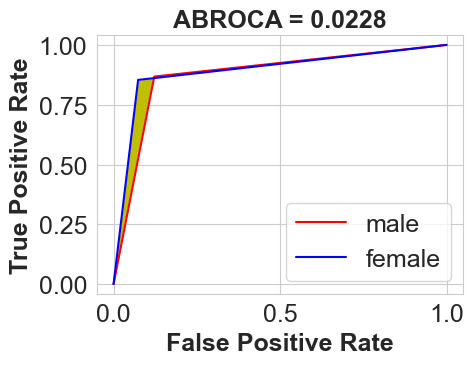

ABROCA: 0.02278924319605462


<Figure size 640x480 with 0 Axes>

In [8]:
run_eval(dataset='german-credit', algorithm='DT')

Length: 1000
Number of columns: 22
NaN per column (top):
 checking-account                         0
duration                                 0
marital-status                           0
sex                                      0
foreign-worker                           0
telephone                                0
number-people-provide-maintenance-for    0
job                                      0
existing-credits                         0
housing                                  0
other-installment                        0
age                                      0
property                                 0
residence-since                          0
other-debtors                            0
installment-rate                         0
employment-since                         0
savings-account                          0
credit-amount                            0
purpose                                  0
dtype: int64
Class imbalance:
 class-label
1    500
0    500
Name: count, dtype: i

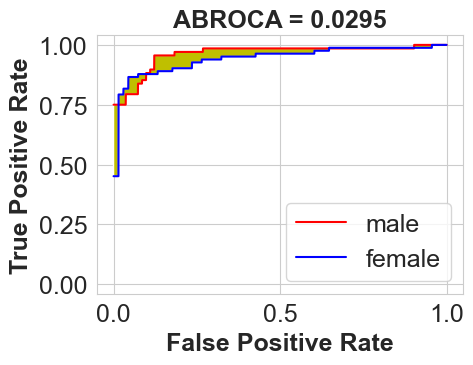

ABROCA: 0.0295007196736119


<Figure size 640x480 with 0 Axes>

In [9]:
run_eval(dataset='german-credit', algorithm='NB')

Length: 1000
Number of columns: 22
NaN per column (top):
 checking-account                         0
duration                                 0
marital-status                           0
sex                                      0
foreign-worker                           0
telephone                                0
number-people-provide-maintenance-for    0
job                                      0
existing-credits                         0
housing                                  0
other-installment                        0
age                                      0
property                                 0
residence-since                          0
other-debtors                            0
installment-rate                         0
employment-since                         0
savings-account                          0
credit-amount                            0
purpose                                  0
dtype: int64
Class imbalance:
 class-label
1    500
0    500
Name: count, dtype: i

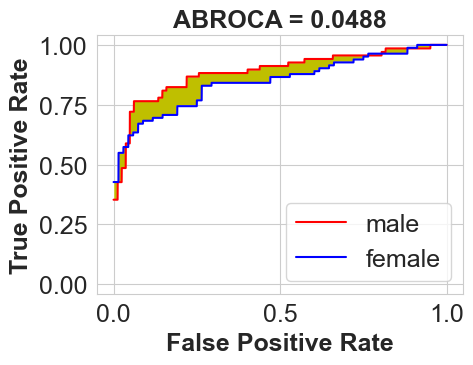

ABROCA: 0.04882401510949182


<Figure size 640x480 with 0 Axes>

In [10]:
run_eval(dataset='german-credit', algorithm='MLP')

Length: 1000
Number of columns: 22
NaN per column (top):
 checking-account                         0
duration                                 0
marital-status                           0
sex                                      0
foreign-worker                           0
telephone                                0
number-people-provide-maintenance-for    0
job                                      0
existing-credits                         0
housing                                  0
other-installment                        0
age                                      0
property                                 0
residence-since                          0
other-debtors                            0
installment-rate                         0
employment-since                         0
savings-account                          0
credit-amount                            0
purpose                                  0
dtype: int64
Class imbalance:
 class-label
1    500
0    500
Name: count, dtype: i

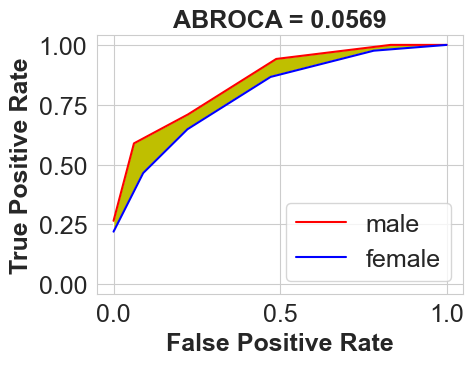

ABROCA: 0.056850787010093336


<Figure size 640x480 with 0 Axes>

In [11]:
run_eval(dataset='german-credit', algorithm='kNN')

In [12]:
run_eval(dataset='german-credit', algorithm='Ada')

Length: 1000
Number of columns: 22
NaN per column (top):
 checking-account                         0
duration                                 0
marital-status                           0
sex                                      0
foreign-worker                           0
telephone                                0
number-people-provide-maintenance-for    0
job                                      0
existing-credits                         0
housing                                  0
other-installment                        0
age                                      0
property                                 0
residence-since                          0
other-debtors                            0
installment-rate                         0
employment-since                         0
savings-account                          0
credit-amount                            0
purpose                                  0
dtype: int64
Class imbalance:
 class-label
1    500
0    500
Name: count, dtype: i

TypeError: BaseEnsemble.__init__() got an unexpected keyword argument 'base_estimator'

In [13]:
run_eval(dataset='german-credit', algorithm='Agar')

Length: 1000
Number of columns: 22
NaN per column (top):
 checking-account                         0
duration                                 0
marital-status                           0
sex                                      0
foreign-worker                           0
telephone                                0
number-people-provide-maintenance-for    0
job                                      0
existing-credits                         0
housing                                  0
other-installment                        0
age                                      0
property                                 0
residence-since                          0
other-debtors                            0
installment-rate                         0
employment-since                         0
savings-account                          0
credit-amount                            0
purpose                                  0
dtype: int64
Class imbalance:
 class-label
1    500
0    500
Name: count, dtype: i

TypeError: ExponentiatedGradient.__init__() takes 3 positional arguments but 7 were given

In [11]:
run_eval(dataset='german-credit', algorithm='DT', preprocessing_algorithm='DIR')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.6221410168778589, 'accuracy': 0.6766666666666666, 'f1-score': 0.7662650602409637, 'fairness': -0.07354202401372212}
Equal opportunity
{'balanced_accuracy': 0.6221410168778589, 'accuracy': 0.6766666666666666, 'f1-score': 0.7662650602409637, 'fairness': 0.09717514124293791, 'TPR_protected': 0.8305084745762712, 'TPR_non_protected': 0.7333333333333333, 'TNR_protected': 0.4482758620689655, 'TNR_non_protected': 0.5}
Equalized odds
{'balanced_accuracy': 0.6221410168778589, 'accuracy': 0.6766666666666666, 'f1-score': 0.7662650602409637, 'fairness': 0.1488992791739724, 'TPR_protected': 0.8305084745762712, 'TPR_non_protected': 0.7333333333333333, 'TNR_protected': 0.4482758620689655, 'TNR_non_protected': 0.5}
Predictive parity
{'balanced_accuracy': 0.6221410168778589, 'accuracy': 0.6766666666666666, 'f1-score': 0.7662650602409

In [12]:
run_eval(dataset='german-credit', algorithm='NB', preprocessing_algorithm='DIR')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.6391503233608496, 'accuracy': 0.7133333333333334, 'f1-score': 0.8009259259259259, 'fairness': -0.009433962264150941}
Equal opportunity
{'balanced_accuracy': 0.6391503233608496, 'accuracy': 0.7133333333333334, 'f1-score': 0.8009259259259259, 'fairness': 0.051073446327683625, 'TPR_protected': 0.864406779661017, 'TPR_non_protected': 0.8133333333333334, 'TNR_protected': 0.4827586206896552, 'TNR_non_protected': 0.43548387096774194}
Equalized odds
{'balanced_accuracy': 0.6391503233608496, 'accuracy': 0.7133333333333334, 'f1-score': 0.8009259259259259, 'fairness': 0.09834819604959688, 'TPR_protected': 0.864406779661017, 'TPR_non_protected': 0.8133333333333334, 'TNR_protected': 0.4827586206896552, 'TNR_non_protected': 0.43548387096774194}
Predictive parity
{'balanced_accuracy': 0.6391503233608496, 'accuracy': 0.713333333333

In [13]:
run_eval(dataset='german-credit', algorithm='MLP', preprocessing_algorithm='DIR')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.5675377254324623, 'accuracy': 0.7, 'f1-score': 0.8076923076923076, 'fairness': -0.032590051457976}
Equal opportunity
{'balanced_accuracy': 0.5675377254324623, 'accuracy': 0.7, 'f1-score': 0.8076923076923076, 'fairness': 0.062485875706214666, 'TPR_protected': 0.9491525423728814, 'TPR_non_protected': 0.8866666666666667, 'TNR_protected': 0.2413793103448276, 'TNR_non_protected': 0.22580645161290322}
Equalized odds
{'balanced_accuracy': 0.5675377254324623, 'accuracy': 0.7, 'f1-score': 0.8076923076923076, 'fairness': 0.07805873443813904, 'TPR_protected': 0.9491525423728814, 'TPR_non_protected': 0.8866666666666667, 'TNR_protected': 0.2413793103448276, 'TNR_non_protected': 0.22580645161290322}
Predictive parity
{'balanced_accuracy': 0.5675377254324623, 'accuracy': 0.7, 'f1-score': 0.8076923076923076, 'fairness': 0.016857911

In [14]:
run_eval(dataset='german-credit', algorithm='kNN', preprocessing_algorithm='DIR')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.511803985488196, 'accuracy': 0.6266666666666667, 'f1-score': 0.7500000000000001, 'fairness': -0.014365351629502476}
Equal opportunity
{'balanced_accuracy': 0.511803985488196, 'accuracy': 0.6266666666666667, 'f1-score': 0.7500000000000001, 'fairness': 0.060790960451977405, 'TPR_protected': 0.847457627118644, 'TPR_non_protected': 0.7866666666666666, 'TNR_protected': 0.27586206896551724, 'TNR_non_protected': 0.1935483870967742}
Equalized odds
{'balanced_accuracy': 0.511803985488196, 'accuracy': 0.6266666666666667, 'f1-score': 0.7500000000000001, 'fairness': 0.14310464232072045, 'TPR_protected': 0.847457627118644, 'TPR_non_protected': 0.7866666666666666, 'TNR_protected': 0.27586206896551724, 'TNR_non_protected': 0.1935483870967742}
Predictive parity
{'balanced_accuracy': 0.511803985488196, 'accuracy': 0.6266666666666667

In [16]:
run_eval(dataset='german-credit', algorithm='DT', preprocessing_algorithm='LFR')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.5331510594668489, 'accuracy': 0.6866666666666666, 'f1-score': 0.8041666666666667, 'fairness': -0.05638936535162953}
Equal opportunity
{'balanced_accuracy': 0.5331510594668489, 'accuracy': 0.6866666666666666, 'f1-score': 0.8041666666666667, 'fairness': 0.059435028248587596, 'TPR_protected': 0.9661016949152542, 'TPR_non_protected': 0.9066666666666666, 'TNR_protected': 0.10344827586206896, 'TNR_non_protected': 0.16129032258064516}
Equalized odds
{'balanced_accuracy': 0.5331510594668489, 'accuracy': 0.6866666666666666, 'f1-score': 0.8041666666666667, 'fairness': 0.11727707496716379, 'TPR_protected': 0.9661016949152542, 'TPR_non_protected': 0.9066666666666666, 'TNR_protected': 0.10344827586206896, 'TNR_non_protected': 0.16129032258064516}
Predictive parity
{'balanced_accuracy': 0.5331510594668489, 'accuracy': 0.686666666

In [17]:
run_eval(dataset='german-credit', algorithm='NB', preprocessing_algorithm='LFR')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.5057574004942426, 'accuracy': 0.32, 'f1-score': 0.06422018348623854, 'fairness': -0.021869639794168096}
Equal opportunity
{'balanced_accuracy': 0.5057574004942426, 'accuracy': 0.32, 'f1-score': 0.06422018348623854, 'fairness': 0.0005649717514124297, 'TPR_protected': 0.03389830508474576, 'TPR_non_protected': 0.03333333333333333, 'TNR_protected': 0.9310344827586207, 'TNR_non_protected': 1.0}
Equalized odds
{'balanced_accuracy': 0.5057574004942426, 'accuracy': 0.32, 'f1-score': 0.06422018348623854, 'fairness': 0.06953048899279177, 'TPR_protected': 0.03389830508474576, 'TPR_non_protected': 0.03333333333333333, 'TNR_protected': 0.9310344827586207, 'TNR_non_protected': 1.0}
Predictive parity
{'balanced_accuracy': 0.5057574004942426, 'accuracy': 0.32, 'f1-score': 0.06422018348623854, 'fairness': 0.5, 'TPR_protected': 0.033

In [18]:
run_eval(dataset='german-credit', algorithm='MLP', preprocessing_algorithm='LFR')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.5, 'accuracy': 0.6966666666666667, 'f1-score': 0.8212180746561886, 'fairness': 0.0}
Equal opportunity
{'balanced_accuracy': 0.5, 'accuracy': 0.6966666666666667, 'f1-score': 0.8212180746561886, 'fairness': 0.0, 'TPR_protected': 1.0, 'TPR_non_protected': 1.0, 'TNR_protected': 0.0, 'TNR_non_protected': 0.0}
Equalized odds
{'balanced_accuracy': 0.5, 'accuracy': 0.6966666666666667, 'f1-score': 0.8212180746561886, 'fairness': 0.0, 'TPR_protected': 1.0, 'TPR_non_protected': 1.0, 'TNR_protected': 0.0, 'TNR_non_protected': 0.0}
Predictive parity
{'balanced_accuracy': 0.5, 'accuracy': 0.6966666666666667, 'f1-score': 0.8212180746561886, 'fairness': 0.037092624356775294, 'TPR_protected': 1.0, 'TPR_non_protected': 1.0, 'TNR_protected': 0.0, 'TNR_non_protected': 0.0}
Predictive equality
{'balanced_accuracy': 0.5, 'accuracy': 0.69

In [22]:
run_eval(dataset='german-credit', algorithm='kNN', preprocessing_algorithm='LFR')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.4950838635049162, 'accuracy': 0.4866666666666667, 'f1-score': 0.5625, 'fairness': 0.14386792452830188}
Equal opportunity
{'balanced_accuracy': 0.4950838635049162, 'accuracy': 0.4866666666666667, 'f1-score': 0.5625, 'fairness': 0.11683615819209042, 'TPR_protected': 0.3898305084745763, 'TPR_non_protected': 0.5066666666666667, 'TNR_protected': 0.6551724137931034, 'TNR_non_protected': 0.45161290322580644}
Equalized odds
{'balanced_accuracy': 0.4950838635049162, 'accuracy': 0.4866666666666667, 'f1-score': 0.5625, 'fairness': 0.3203956687593874, 'TPR_protected': 0.3898305084745763, 'TPR_non_protected': 0.5066666666666667, 'TNR_protected': 0.6551724137931034, 'TNR_non_protected': 0.45161290322580644}
Predictive parity
{'balanced_accuracy': 0.4950838635049162, 'accuracy': 0.4866666666666667, 'f1-score': 0.5625, 'fairness': 

In [23]:
run_eval(dataset='german-credit', algorithm='DT', postprocessing_algorithm='EOP')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.5953783059046217, 'accuracy': 0.6566666666666666, 'f1-score': 0.7529976019184652, 'fairness': 0.04845626072041165}
Equal opportunity
{'balanced_accuracy': 0.5953783059046217, 'accuracy': 0.6566666666666666, 'f1-score': 0.7529976019184652, 'fairness': 0.016045197740112926, 'TPR_protected': 0.7627118644067796, 'TPR_non_protected': 0.7466666666666667, 'TNR_protected': 0.5517241379310345, 'TNR_non_protected': 0.3870967741935484}
Equalized odds
{'balanced_accuracy': 0.5953783059046217, 'accuracy': 0.6566666666666666, 'f1-score': 0.7529976019184652, 'fairness': 0.18067256147759903, 'TPR_protected': 0.7627118644067796, 'TPR_non_protected': 0.7466666666666667, 'TNR_protected': 0.5517241379310345, 'TNR_non_protected': 0.3870967741935484}
Predictive parity
{'balanced_accuracy': 0.5953783059046217, 'accuracy': 0.65666666666666

In [24]:
run_eval(dataset='german-credit', algorithm='NB', postprocessing_algorithm='EOP')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.6286082338713918, 'accuracy': 0.69, 'f1-score': 0.7790973871733966, 'fairness': -0.09348198970840482}
Equal opportunity
{'balanced_accuracy': 0.6286082338713918, 'accuracy': 0.69, 'f1-score': 0.7790973871733966, 'fairness': 0.1346892655367231, 'TPR_protected': 0.8813559322033898, 'TPR_non_protected': 0.7466666666666667, 'TNR_protected': 0.4482758620689655, 'TNR_non_protected': 0.4838709677419355}
Equalized odds
{'balanced_accuracy': 0.6286082338713918, 'accuracy': 0.69, 'f1-score': 0.7790973871733966, 'fairness': 0.1702843712096931, 'TPR_protected': 0.8813559322033898, 'TPR_non_protected': 0.7466666666666667, 'TNR_protected': 0.4482758620689655, 'TNR_non_protected': 0.4838709677419355}
Predictive parity
{'balanced_accuracy': 0.6286082338713918, 'accuracy': 0.69, 'f1-score': 0.7790973871733966, 'fairness': 0.01307189

In [25]:
run_eval(dataset='german-credit', algorithm='MLP', postprocessing_algorithm='EOP')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.5991902834008097, 'accuracy': 0.6533333333333333, 'f1-score': 0.7475728155339806, 'fairness': -0.08769296740994859}
Equal opportunity
{'balanced_accuracy': 0.5991902834008097, 'accuracy': 0.6533333333333333, 'f1-score': 0.7475728155339806, 'fairness': 0.10689265536723169, 'TPR_protected': 0.8135593220338984, 'TPR_non_protected': 0.7066666666666667, 'TNR_protected': 0.41379310344827586, 'TNR_non_protected': 0.4838709677419355}
Equalized odds
{'balanced_accuracy': 0.5991902834008097, 'accuracy': 0.6533333333333333, 'f1-score': 0.7475728155339806, 'fairness': 0.17697051966089133, 'TPR_protected': 0.8135593220338984, 'TPR_non_protected': 0.7066666666666667, 'TNR_protected': 0.41379310344827586, 'TNR_non_protected': 0.4838709677419355}
Predictive parity
{'balanced_accuracy': 0.5991902834008097, 'accuracy': 0.653333333333

In [26]:
run_eval(dataset='german-credit', algorithm='kNN', postprocessing_algorithm='EOP')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.5309427414690573, 'accuracy': 0.6533333333333333, 'f1-score': 0.7719298245614034, 'fairness': 0.08769296740994859}
Equal opportunity
{'balanced_accuracy': 0.5309427414690573, 'accuracy': 0.6533333333333333, 'f1-score': 0.7719298245614034, 'fairness': 0.08700564971751412, 'TPR_protected': 0.7796610169491526, 'TPR_non_protected': 0.8666666666666667, 'TNR_protected': 0.27586206896551724, 'TNR_non_protected': 0.1935483870967742}
Equalized odds
{'balanced_accuracy': 0.5309427414690573, 'accuracy': 0.6533333333333333, 'f1-score': 0.7719298245614034, 'fairness': 0.16931933158625717, 'TPR_protected': 0.7796610169491526, 'TPR_non_protected': 0.8666666666666667, 'TNR_protected': 0.27586206896551724, 'TNR_non_protected': 0.1935483870967742}
Predictive parity
{'balanced_accuracy': 0.5309427414690573, 'accuracy': 0.6533333333333

In [27]:
run_eval(dataset='german-credit', algorithm='DT', postprocessing_algorithm='CEP')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.5953783059046217, 'accuracy': 0.6566666666666666, 'f1-score': 0.7529976019184652, 'fairness': 0.04845626072041165}
Equal opportunity
{'balanced_accuracy': 0.5953783059046217, 'accuracy': 0.6566666666666666, 'f1-score': 0.7529976019184652, 'fairness': 0.016045197740112926, 'TPR_protected': 0.7627118644067796, 'TPR_non_protected': 0.7466666666666667, 'TNR_protected': 0.5517241379310345, 'TNR_non_protected': 0.3870967741935484}
Equalized odds
{'balanced_accuracy': 0.5953783059046217, 'accuracy': 0.6566666666666666, 'f1-score': 0.7529976019184652, 'fairness': 0.18067256147759903, 'TPR_protected': 0.7627118644067796, 'TPR_non_protected': 0.7466666666666667, 'TNR_protected': 0.5517241379310345, 'TNR_non_protected': 0.3870967741935484}
Predictive parity
{'balanced_accuracy': 0.5953783059046217, 'accuracy': 0.65666666666666

In [28]:
run_eval(dataset='german-credit', algorithm='NB', postprocessing_algorithm='CEP')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.6153057468846943, 'accuracy': 0.7233333333333334, 'f1-score': 0.8175824175824176, 'fairness': 0.11513722126929671}
Equal opportunity
{'balanced_accuracy': 0.6153057468846943, 'accuracy': 0.7233333333333334, 'f1-score': 0.8175824175824176, 'fairness': 0.011977401129943499, 'TPR_protected': 0.8813559322033898, 'TPR_non_protected': 0.8933333333333333, 'TNR_protected': 0.5517241379310345, 'TNR_non_protected': 0.24193548387096775}
Equalized odds
{'balanced_accuracy': 0.6153057468846943, 'accuracy': 0.7233333333333334, 'f1-score': 0.8175824175824176, 'fairness': 0.3217660551900102, 'TPR_protected': 0.8813559322033898, 'TPR_non_protected': 0.8933333333333333, 'TNR_protected': 0.5517241379310345, 'TNR_non_protected': 0.24193548387096775}
Predictive parity
{'balanced_accuracy': 0.6153057468846943, 'accuracy': 0.7233333333333

In [29]:
run_eval(dataset='german-credit', algorithm='MLP', postprocessing_algorithm='CEP')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.5667490404332509, 'accuracy': 0.66, 'f1-score': 0.7671232876712328, 'fairness': 0.05102915951972553}
Equal opportunity
{'balanced_accuracy': 0.5667490404332509, 'accuracy': 0.66, 'f1-score': 0.7671232876712328, 'fairness': 0.013559322033898313, 'TPR_protected': 0.8135593220338984, 'TPR_non_protected': 0.8, 'TNR_protected': 0.4482758620689655, 'TNR_non_protected': 0.27419354838709675}
Equalized odds
{'balanced_accuracy': 0.5667490404332509, 'accuracy': 0.66, 'f1-score': 0.7671232876712328, 'fairness': 0.18764163571576709, 'TPR_protected': 0.8135593220338984, 'TPR_non_protected': 0.8, 'TNR_protected': 0.4482758620689655, 'TNR_non_protected': 0.27419354838709675}
Predictive parity
{'balanced_accuracy': 0.5667490404332509, 'accuracy': 0.66, 'f1-score': 0.7671232876712328, 'fairness': 0.022727272727272707, 'TPR_protected

In [30]:
run_eval(dataset='german-credit', algorithm='kNN', postprocessing_algorithm='CEP')

Length: 1000
Number of attribute: 22
Length (cleaned): 1000
Class imbalance: 
 1    700
0    300
Name: class-label, dtype: int64
Statistical parity:
{'balanced_accuracy': 0.5257111309742889, 'accuracy': 0.6633333333333333, 'f1-score': 0.7837259100642399, 'fairness': 0.1395797598627787}
Equal opportunity
{'balanced_accuracy': 0.5257111309742889, 'accuracy': 0.6633333333333333, 'f1-score': 0.7837259100642399, 'fairness': 0.13367231638418076, 'TPR_protected': 0.7796610169491526, 'TPR_non_protected': 0.9133333333333333, 'TNR_protected': 0.27586206896551724, 'TNR_non_protected': 0.12903225806451613}
Equalized odds
{'balanced_accuracy': 0.5257111309742889, 'accuracy': 0.6633333333333333, 'f1-score': 0.7837259100642399, 'fairness': 0.28050212728518187, 'TPR_protected': 0.7796610169491526, 'TPR_non_protected': 0.9133333333333333, 'TNR_protected': 0.27586206896551724, 'TNR_non_protected': 0.12903225806451613}
Predictive parity
{'balanced_accuracy': 0.5257111309742889, 'accuracy': 0.663333333333